In [1]:
from pathlib import Path
from typing import Final

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch

from confidence import (
    evaluate_reject_rule,
    extract_confidence_data,
    select_reject_threshold,
    print_reject_results,
    build_failure_data
)
from dataset import CLASS_NAMES
from predict import (
    compute_confusion_matrix,
    load_model,
    load_prediction_data,
    print_confusion_matrix,
    print_results,
    run_inference,
)
from profiling import profile_model, print_profile
from train import classification_metrics
from visualisation import plot_embeddings, reduce_embeddings

## Multi-Layer GNN for Facebook Page Classification
### COMP3710 Working Prototype Project in the Era of Artificial Intelligence
#### Derek McKinney (dm-uq)
#### SN: 45506053

### Final Evaluation
<br>
This notebook provides the final comparative evaluation of the frozen MLP baseline and GCN models.<br>
It reuses the project evaluation utilities implemented in predict.py and supporting modules, while providing<br>
additional analysis and interpretation of classification performance, computational cost, confidence behaviour,<br>
learned representations, and representative failure cases.<br>
<br>
References:

Facebook Page-Page dataset:
    https://github.com/gayanku/facebook_page-page_dataset

PyG FacebookPagePage:
    https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.datasets.FacebookPagePage.html

#### Config and Constants

In [2]:
# constants
SEED: Final[int] = 808

# plot styling
sns.set_theme(context="notebook", style="whitegrid")

# local paths
PROJECT_DIR: Final[Path] = Path.cwd().resolve()
CHECKPOINTS_DIR: Final[Path] = PROJECT_DIR / "checkpoints"
IMAGES_DIR: Final[Path] = PROJECT_DIR / "images" / "evaluation"

MLP_CHECKPOINT: Final[Path] = CHECKPOINTS_DIR / "mlp_final.pt"
GCN_CHECKPOINT: Final[Path] = CHECKPOINTS_DIR / "gcn_final.pt"

In [3]:
# device configuration
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {device}")

if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
NVIDIA GeForce GTX 950M


#### Frozen Models
Model architectures and hyperparameters were fixed before final test evaluation.<br>
The same stratified 60/20/20 split and seed (808) are used throughout.<br>
The held-out test set has been reserved for final evaluation and was not used in model selection.<br>

| MLP baseline       | GCN                |
|--------------------|--------------------|
| 3 layers           | 4 layers           |
| 128 input features | 128 input features |
| 64 hidden channels | 64 hidden channels |
| 4 output classes   | 4 output classes   |
| ReLU               | ReLU               |
| Dropout: 0.50      | Dropout: 0.55      |
| `mlp_final.pt`     | `gcn_final.pt`     |

#### Load Data and Frozen Models

In [4]:
# load evaluation data
dataset, data = load_prediction_data()

print(data)  # data check

Data(x=[22470, 128], edge_index=[2, 342004], y=[22470], train_mask=[22470], val_mask=[22470], test_mask=[22470])


In [5]:
# Load frozen final models
mlp, _ = load_model(
    model_name="mlp",
    in_channels=data.num_node_features,
    out_channels=dataset.num_classes,
    requested_device=device,
)

gcn, _ = load_model(
    model_name="gcn",
    in_channels=data.num_node_features,
    out_channels=dataset.num_classes,
    requested_device=device,
)

# move graph tensors to evaluation device
data = data.to(device)

print(f"MLP checkpoint: {MLP_CHECKPOINT.name}")  # MLP check
print(f"GCN checkpoint: {GCN_CHECKPOINT.name}")  # GCN check

MLP checkpoint: mlp_final.pt
GCN checkpoint: gcn_final.pt


### Final MLP Baseline Evaluation

In [6]:
# run final MLP inference
mlp_logits = run_inference(
    model=mlp,
    data=data,
)

print(f"MLP logits shape: {mlp_logits.shape}\n")

MLP logits shape: torch.Size([22470, 4])



In [7]:
# compute held-out test metrics
mlp_metrics = classification_metrics(
    logits=mlp_logits,
    labels=data.y,
    mask=data.test_mask,
)

print_results(
    model_name="MLP",
    metrics=mlp_metrics,
)


MLP Aggregate Test Results
--------------------------
Accuracy:         82.24%
Macro Precision:  81.18%
Macro Recall:     79.89%
Macro F1:         80.37%
Macro AUROC:      95.49%

MLP Per-Class Results
--------------------------------------------------------
Class            Precision    Recall        F1   Support
--------------------------------------------------------
tvshow              82.59%    83.99%    83.28%      1299
government          84.01%    85.90%    84.94%      1376
company             83.11%    87.44%    85.22%      1154
politician          75.00%    62.26%    68.04%       665



In [8]:
# generate confusion matrix for held-out test metrics
mlp_confusion = compute_confusion_matrix(
    logits=mlp_logits,
    labels=data.y,
    mask=data.test_mask,
)

print_confusion_matrix(
    model_name="MLP",
    matrix=mlp_confusion,
)


MLP Confusion Matrix
--------------------------------------------------------------
Actual \ Pred.      tvshow  government     company  politician
--------------------------------------------------------------
tvshow                1091          89          28          91
government              65        1182         107          22
company                 17         103        1009          25
politician             148          33          70         414



### Final GCN Evaluation

In [9]:
# run final GCN inference
gcn_logits = run_inference(
    model=gcn,
    data=data,
)

print(f"GCN logits shape: {gcn_logits.shape}\n")

GCN logits shape: torch.Size([22470, 4])



In [10]:
# compute held-out test metrics
gcn_metrics = classification_metrics(
    logits=gcn_logits,
    labels=data.y,
    mask=data.test_mask,
)

print_results(
    model_name="GCN",
    metrics=gcn_metrics,
)


GCN Aggregate Test Results
--------------------------
Accuracy:         95.26%
Macro Precision:  95.02%
Macro Recall:     94.88%
Macro F1:         94.95%
Macro AUROC:      99.25%

GCN Per-Class Results
--------------------------------------------------------
Class            Precision    Recall        F1   Support
--------------------------------------------------------
tvshow              95.25%    94.15%    94.70%      1299
government          95.47%    96.44%    95.95%      1376
company             96.22%    97.05%    96.64%      1154
politician          93.14%    91.88%    92.51%       665



In [11]:
# generate confusion matrix for held-out test metrics
gcn_confusion = compute_confusion_matrix(
    logits=gcn_logits,
    labels=data.y,
    mask=data.test_mask,
)

print_confusion_matrix(
    model_name="GCN",
    matrix=gcn_confusion,
)


GCN Confusion Matrix
--------------------------------------------------------------
Actual \ Pred.      tvshow  government     company  politician
--------------------------------------------------------------
tvshow                1223          32           5          39
government              18        1327          30           1
company                  1          28        1120           5
politician              42           3           9         611



### GCN vs MLP Comparison
The GCN substantially outperformed the feature-only MLP across the held-out test metrics, including macro-F1 and AUROC.<br>
This improvement was also consistent across all four classes, with the largest practical gain occurring for the
comparatively<br>
difficult politician class.<br>

The following analyses examine whether this classification performance increase is accompanied by additional
computational<br>cost, a clearer latent class structure, and an improvement in confidence behaviour.

### Computational Profiling
The frozen MLP and GCN models were profiled under the same hardware and
inference conditions.<br>Parameter count, full-graph inference latency, and peak
PyTorch GPU memory allocation were measured<br>using the profiling functions implemented in `profiling.py`.

#### MLP Profiling

In [12]:
# profile frozen final MLP model
mlp_profile = profile_model(
    model=mlp,
    data=data,
    device=device,
)

In [13]:
# display profiling results for final MLP model
print_profile("MLP", mlp_profile)


MLP Profiling Results
------------------------------
Parameters:         12,676
Mean latency:       2.34 ms
Median latency:     2.31 ms
Peak VRAM:          36.32 MiB



#### GCN Profiling

In [14]:
# profile frozen final GCN model
gcn_profile = profile_model(
    model=gcn,
    data=data,
    device=device,
)

In [15]:
# display profiling results for final GCN model
print_profile("GCN", gcn_profile)


GCN Profiling Results
------------------------------
Parameters:         16,836
Mean latency:       83.44 ms
Median latency:     83.43 ms
Peak VRAM:          226.55 MiB



The GCN contains 16,836 trainable parameters; approximately 33% more than the MLP baseline's 12,676.<br>
The difference in inference cost is much larger - the full-graph latency increases approximately 36x (MLP: 2.34 ms,<br>
GCN: 83.44 ms), while peak PyTorch-allocated GPU memory increases approximately 6.2x (MLP: 36.32 MiB, GCN: 226.55
 MiB).<br>

This reflects the additional graph computation performed by the GCN, where each layer propagates and aggregates<br>
information across neighbouring nodes rather than transforming node features independently.<br>
Despite the relative increases, full-graph GCN inference remains below 0.1 seconds on the local evaluation hardware.

### Embedding Visualisation
The learned representations from the frozen MLP and GCN models were reduced from 64 dimensions to 2 dimensions using<br>
UMAP, providing a qualitative comparison of the class structure captured by each model.<br>

In [16]:
# extract learned node embeddings
mlp.eval()
gcn.eval()

with torch.inference_mode():
    mlp_embeddings = mlp.extract_embeddings(
        data.x,
    )

    gcn_embeddings = gcn.extract_embeddings(
        data.x,
        data.edge_index,
    )

print(f"MLP embeddings: {mlp_embeddings.shape}")
print(f"GCN embeddings: {gcn_embeddings.shape}")

MLP embeddings: torch.Size([22470, 64])
GCN embeddings: torch.Size([22470, 64])


In [17]:
# reduce learned representations to two dimensions
mlp_embedding_2d = reduce_embeddings(
    embeddings=mlp_embeddings,
)

gcn_embedding_2d = reduce_embeddings(
    embeddings=gcn_embeddings,
)

print(f"MLP UMAP: {mlp_embedding_2d.shape}")
print(f"GCN UMAP: {gcn_embedding_2d.shape}")

MLP UMAP: (22470, 2)
GCN UMAP: (22470, 2)


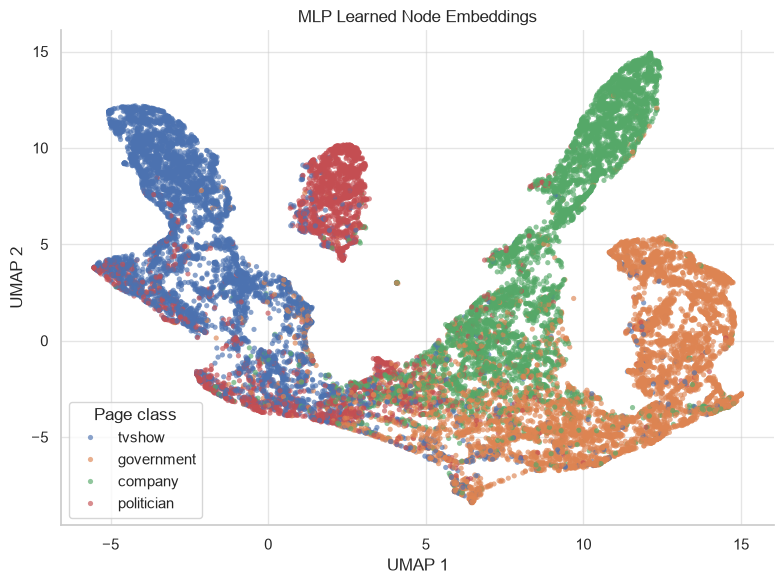

In [18]:
# plot MLP embedding using ground-truth class labels
mlp_figure = plot_embeddings(
    embedding_2d=mlp_embedding_2d,
    labels=data.y,
    model_name="MLP",
)

plt.show()

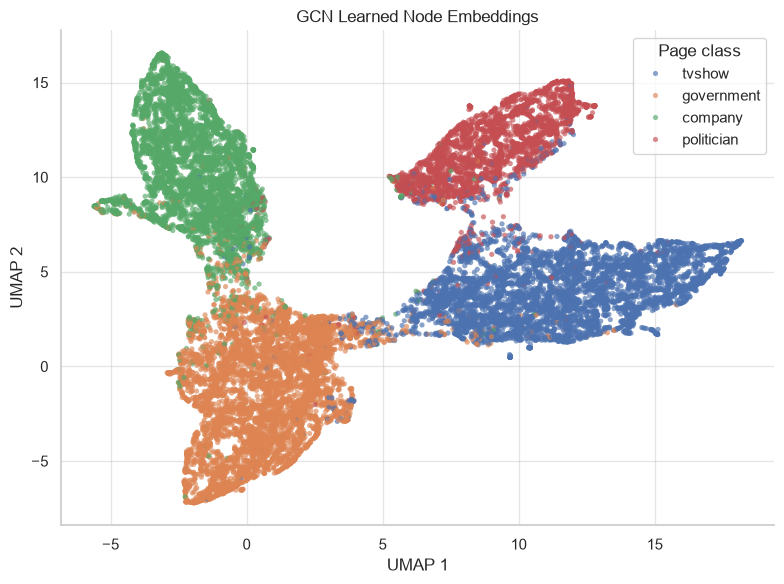

In [19]:
# plot GCN embedding using ground-truth class labels
gcn_figure = plot_embeddings(
    embedding_2d=gcn_embedding_2d,
    labels=data.y,
    model_name="GCN",
)

plt.show()

The UMAP projections reveal a clear difference in the structure learned by the two models.<br>
The MLP embedding shows substantial overlap between classes, particularly between `tvshow` and `politician`,<br>
whereas the GCN embedding forms much more distinct class regions, consistent with its stronger held-out<br>
classification performance.

Note: Ground-truth labels were used only to colour the projected points after dimensionality reduction and<br>
were not provided to UMAP. This preserves the projection as an unsupervised view of the structure present<br>
in the learned representations.

### Confidence and Reject-Option Analysis

Prediction confidence is measured using the maximum softmax response i.e. the largest softmax value assigned<br>
to any class.<br>
A reject-option rule is used to automatically accept high-confidence predictions above a chosen threshold,<br>
while routing lower-confidence cases for review by human specialists.

For each model, the global confidence threshold is selected using validation data to maximise automated coverage<br>
while constraining the empirical error rate among accepted predictions to at most 1%.<br>
Predictions with confidence greater than, or equal to, the selected threshold are automatically accepted.<br>
The resulting threshold is then fixed and applied, unchanged, to the held-out test data.

In [20]:
# get validation confidence data for threshold selection
mlp_val_confidence = extract_confidence_data(
    logits=mlp_logits,
    labels=data.y,
    mask=data.val_mask,
)

gcn_val_confidence = extract_confidence_data(
    logits=gcn_logits,
    labels=data.y,
    mask=data.val_mask,
)

#### Choose threshold using validation only

In [21]:
# select global reject thresholds
MAX_VALIDATION_RISK: Final[float] = 0.01  # allow at most 1% validation risk

mlp_threshold = select_reject_threshold(
    confidence=mlp_val_confidence["confidence"],
    correct=mlp_val_confidence["correct"],
    max_risk=MAX_VALIDATION_RISK,
)

gcn_threshold = select_reject_threshold(
    confidence=gcn_val_confidence["confidence"],
    correct=gcn_val_confidence["correct"],
    max_risk=MAX_VALIDATION_RISK,
)

print(f"MLP threshold: {mlp_threshold:.6f}")
print(f"GCN threshold: {gcn_threshold:.6f}")

MLP threshold: 0.997656
GCN threshold: 0.994863


#### Validation Reject-Option results

In [22]:
# evaluate validation coverage and risk at the selected reject thresholds
mlp_val_results = evaluate_reject_rule(
    confidence=mlp_val_confidence["confidence"],
    correct=mlp_val_confidence["correct"],
    threshold=mlp_threshold,
)

gcn_val_results = evaluate_reject_rule(
    confidence=gcn_val_confidence["confidence"],
    correct=gcn_val_confidence["correct"],
    threshold=gcn_threshold,
)

print_reject_results(
    results=mlp_val_results,
    model_name="MLP Validation",
)

print_reject_results(
    results=gcn_val_results,
    model_name="GCN Validation",
)

MLP Validation Reject-Option Results
--------------------------------------
Accepted:                  1,063
Rejected:                  3,431
Accepted errors:              10
Rejected errors:             795
Coverage:                 23.65%
Accepted accuracy:        99.06%
Accepted risk:            0.941%

GCN Validation Reject-Option Results
--------------------------------------
Accepted:                  2,307
Rejected:                  2,187
Accepted errors:              23
Rejected errors:             199
Coverage:                 51.34%
Accepted accuracy:        99.00%
Accepted risk:            0.997%



#### Evaluate fixed thresholds against the test set.

In [23]:
# get test confidence data for fixed-threshold evaluation
mlp_test_confidence = extract_confidence_data(
    logits=mlp_logits,
    labels=data.y,
    mask=data.test_mask,
)

gcn_test_confidence = extract_confidence_data(
    logits=gcn_logits,
    labels=data.y,
    mask=data.test_mask,
)

In [24]:
# evaluate fixed reject-option thresholds on the test set
mlp_test_results = evaluate_reject_rule(
    confidence=mlp_test_confidence["confidence"],
    correct=mlp_test_confidence["correct"],
    threshold=mlp_threshold,
)

gcn_test_results = evaluate_reject_rule(
    confidence=gcn_test_confidence["confidence"],
    correct=gcn_test_confidence["correct"],
    threshold=gcn_threshold,
)

print_reject_results(
    results=mlp_test_results,
    model_name="MLP Test",
)

print_reject_results(
    results=gcn_test_results,
    model_name="GCN Test",
)

MLP Test Reject-Option Results
--------------------------------------
Accepted:                  1,091
Rejected:                  3,403
Accepted errors:              11
Rejected errors:             787
Coverage:                 24.28%
Accepted accuracy:        98.99%
Accepted risk:            1.008%

GCN Test Reject-Option Results
--------------------------------------
Accepted:                  2,264
Rejected:                  2,230
Accepted errors:              21
Rejected errors:             192
Coverage:                 50.38%
Accepted accuracy:        99.07%
Accepted risk:            0.928%



### Failure Analysis
Representative test-set classification failures were selected to examine potential model weaknesses and blind spots,<br>
and whether confidence scores provide useful information for identifying ambiguous predictions.<br>
Cases were chosen to represent distinct failure modes rather than simply sampling errors at random.<br>

Note: Neighbour labels are inspected only during post-hoc failure analysis and were not supplied to the model<br>
during training or message passing.

In [25]:
# combine test predictions, confidence scores, and original node indices
failure_data = build_failure_data(
    mask=data.test_mask,
    mlp_data=mlp_test_confidence,
    gcn_data=gcn_test_confidence,
)

#### Case Type: High-Confidence GCN Error


In [26]:
# identify high-confidence GCN errors
case_mask = (
    (~failure_data["gcn_correct"])
    & (failure_data["gcn_confidence"] >= gcn_threshold)
)

case_positions = np.flatnonzero(case_mask)

# sort incorrect predictions by GCN confidence
case_positions = case_positions[
    np.argsort(
        failure_data["gcn_confidence"][case_positions]
    )[::-1]
]

case_positions[:5]

array([  62, 1502, 3360, 2646, 2017])

In [27]:
# display the five highest-confidence GCN errors
for position in case_positions[:5]:
    position = int(position)

    node_index = int(failure_data["node_index"][position])
    target = int(failure_data["target"][position])
    gcn_prediction = int(
        failure_data["gcn_prediction"][position]
    )
    mlp_prediction = int(
        failure_data["mlp_prediction"][position]
    )
    gcn_confidence = float(
        failure_data["gcn_confidence"][position]
    )
    mlp_confidence = float(
        failure_data["mlp_confidence"][position]
    )

    print(
        f"Node {node_index:>5} | "
        f"True: {CLASS_NAMES[target]:<10} | "
        f"GCN: {CLASS_NAMES[gcn_prediction]:<10} | "
        f"Confidence: {gcn_confidence:.6f} | "
        f"MLP: {CLASS_NAMES[mlp_prediction]:<10} | "
        f"MLP confidence: {mlp_confidence:.6f}"
    )

Node   293 | True: company    | GCN: government | Confidence: 0.999994 | MLP: company    | MLP confidence: 0.999999
Node  7157 | True: company    | GCN: government | Confidence: 0.999964 | MLP: company    | MLP confidence: 1.000000
Node 16813 | True: company    | GCN: government | Confidence: 0.999952 | MLP: government | MLP confidence: 0.547633
Node 13231 | True: tvshow     | GCN: politician | Confidence: 0.999950 | MLP: tvshow     | MLP confidence: 0.724014
Node  9939 | True: tvshow     | GCN: government | Confidence: 0.999873 | MLP: government | MLP confidence: 0.984970


Selected example:

Node   293 | True: company    | GCN: government | Confidence: 0.999994 | MLP: company    | MLP confidence: 0.999999<br>


In [28]:
# inspect the neighbourhood of the failure case (node 293)
node_index = 293
edge_index = data.edge_index

# collect unique neighbours from both edge directions
neighbours = torch.cat(
    (
        edge_index[1, edge_index[0] == node_index],
        edge_index[0, edge_index[1] == node_index],
    )
).unique()

neighbour_labels = data.y[neighbours]

print(f"Node degree: {len(neighbours)}")

# print neighbour class distribution
for class_index, class_name in CLASS_NAMES.items():
    count = int((neighbour_labels == class_index).sum())
    print(f"{class_name:<10}: {count}")

Node degree: 59
tvshow    : 0
government: 56
company   : 2
politician: 1


Node 293 is a notable high-confidence GCN failure.<br>
The MLP classifies it correctly as `company`, while its immediate neighbourhood is overwhelmingly `government`,<br>
suggesting that misleading graph context contributed to the GCN error.

#### Case Type: Low-Confidence GCN Error

In [29]:
# identify low-confidence GCN errors
case_mask = ~failure_data["gcn_correct"]

case_positions = np.flatnonzero(case_mask)

# sort incorrect predictions by increasing GCN confidence
case_positions = case_positions[
    np.argsort(
        failure_data["gcn_confidence"][case_positions]
    )
]

case_positions[:5]

array([2296, 3179, 1996, 3911, 4475])

In [30]:
# display the five lowest-confidence GCN errors
for position in case_positions[:5]:
    position = int(position)

    node_index = int(failure_data["node_index"][position])
    target = int(failure_data["target"][position])
    gcn_prediction = int(
        failure_data["gcn_prediction"][position]
    )
    mlp_prediction = int(
        failure_data["mlp_prediction"][position]
    )
    gcn_confidence = float(
        failure_data["gcn_confidence"][position]
    )
    mlp_confidence = float(
        failure_data["mlp_confidence"][position]
    )

    print(
        f"Node {node_index:>5} | "
        f"True: {CLASS_NAMES[target]:<10} | "
        f"GCN: {CLASS_NAMES[gcn_prediction]:<10} | "
        f"Confidence: {gcn_confidence:.6f} | "
        f"MLP: {CLASS_NAMES[mlp_prediction]:<10} | "
        f"MLP confidence: {mlp_confidence:.6f}"
    )

Node 11463 | True: tvshow     | GCN: government | Confidence: 0.358360 | MLP: government | MLP confidence: 0.892088
Node 15875 | True: politician | GCN: tvshow     | Confidence: 0.386059 | MLP: company    | MLP confidence: 0.348136
Node  9827 | True: politician | GCN: government | Confidence: 0.399317 | MLP: politician | MLP confidence: 0.474687
Node 19624 | True: tvshow     | GCN: government | Confidence: 0.400037 | MLP: company    | MLP confidence: 0.689536
Node 22356 | True: tvshow     | GCN: government | Confidence: 0.401947 | MLP: government | MLP confidence: 0.975788


Selected example:

Node 15875 | True: politician | GCN: tvshow     | Confidence: 0.386059 | MLP: company    | MLP confidence: 0.348136

In [31]:
# inspect the neighbourhood of the failure case (node 15875)
node_index = 15875
edge_index = data.edge_index

# collect unique neighbours from both edge directions
neighbours = torch.cat(
    (
        edge_index[1, edge_index[0] == node_index],
        edge_index[0, edge_index[1] == node_index],
    )
).unique()

neighbour_labels = data.y[neighbours]

print(f"Node degree: {len(neighbours)}")

# print neighbour class distribution
for class_index, class_name in CLASS_NAMES.items():
    count = int((neighbour_labels == class_index).sum())
    print(f"{class_name:<10}: {count}")

Node degree: 2
tvshow    : 0
government: 0
company   : 0
politician: 2


Node 15875 is an ambiguous low-confidence failure.<br>
Both models predict different incorrect classes, while its sparse two-node neighbourhood contains only<br>
`politician` nodes, suggesting that the error cannot be explained by a misleading immediate<br>
neighbourhood alone.<br>
A 'two-hop' neighbourhood check may prove informative.

In [32]:
# collect neighbours of each first-hop neighbour
second_hop_parts = []

for neighbour in neighbours:
    neighbour = int(neighbour)

    # collect connected nodes from both edge directions
    second_hop_parts.extend(
        (
            edge_index[1, edge_index[0] == neighbour],
            edge_index[0, edge_index[1] == neighbour],
        )
    )

# combine and remove duplicate node indices
second_hop_neighbours = torch.cat(second_hop_parts).unique()

# remove nodes already within one hop, leaving exact second-hop neighbours
excluded_nodes = torch.cat(
    (
        torch.tensor(
            [node_index],
            device=edge_index.device,
        ),
        neighbours,
    )
)

# retain only nodes exactly two hops away
second_hop_neighbours = second_hop_neighbours[
    ~torch.isin(second_hop_neighbours, excluded_nodes)
]

second_hop_labels = data.y[second_hop_neighbours]

print(f"Second-hop nodes: {len(second_hop_neighbours)}")

# print second-hop class distribution
for class_index, class_name in CLASS_NAMES.items():
    count = int((second_hop_labels == class_index).sum())
    print(f"{class_name:<10}: {count}")

Second-hop nodes: 6
tvshow    : 0
government: 1
company   : 1
politician: 4


The two-hop neighbourhood check produced six additional nodes: four `politician`, one `government`, one `company`,<br>
and no `tvshow` nodes.<br>
The broader local inspection still does not provide a simple explanation for the GCN prediction at this level,<br>
of analysis.

#### Case Type: MLP Wrong / GCN Correct

In [33]:
# identify cases where the MLP fails but the GCN succeeds
case_mask = (
    (~failure_data["mlp_correct"])
    & failure_data["gcn_correct"]
)

case_positions = np.flatnonzero(case_mask)

# prioritise confident MLP errors where the GCN is correct
case_positions = case_positions[
    np.argsort(
        failure_data["mlp_confidence"][case_positions]
    )[::-1]
]

case_positions[:5]

array([3772,  797, 1038,  858, 2185])

In [34]:
# display the five highest-confidence MLP errors where the GCN is correct
for position in case_positions[:5]:
    position = int(position)

    node_index = int(failure_data["node_index"][position])
    target = int(failure_data["target"][position])
    gcn_prediction = int(
        failure_data["gcn_prediction"][position]
    )
    mlp_prediction = int(
        failure_data["mlp_prediction"][position]
    )
    gcn_confidence = float(
        failure_data["gcn_confidence"][position]
    )
    mlp_confidence = float(
        failure_data["mlp_confidence"][position]
    )

    print(
        f"Node {node_index:>5} | "
        f"True: {CLASS_NAMES[target]:<10} | "
        f"GCN: {CLASS_NAMES[gcn_prediction]:<10} | "
        f"Confidence: {gcn_confidence:.6f} | "
        f"MLP: {CLASS_NAMES[mlp_prediction]:<10} | "
        f"MLP confidence: {mlp_confidence:.6f}"
    )

Node 18891 | True: government | GCN: government | Confidence: 0.987778 | MLP: company    | MLP confidence: 1.000000
Node  3815 | True: government | GCN: government | Confidence: 0.975594 | MLP: company    | MLP confidence: 0.999989
Node  4920 | True: politician | GCN: politician | Confidence: 0.932839 | MLP: company    | MLP confidence: 0.999939
Node  4118 | True: politician | GCN: politician | Confidence: 0.997871 | MLP: government | MLP confidence: 0.999909
Node 10877 | True: politician | GCN: politician | Confidence: 0.919615 | MLP: tvshow     | MLP confidence: 0.999856


Selected example:

Node  4118 | True: politician | GCN: politician | Confidence: 0.997871 | MLP: government | MLP confidence: 0.999909

In [35]:
# inspect the neighbourhood of the failure case (node 4118)
node_index = 4118
edge_index = data.edge_index

# collect unique neighbours from both edge directions
neighbours = torch.cat(
    (
        edge_index[1, edge_index[0] == node_index],
        edge_index[0, edge_index[1] == node_index],
    )
).unique()

neighbour_labels = data.y[neighbours]

print(f"Node degree: {len(neighbours)}")

# print neighbour class distribution
for class_index, class_name in CLASS_NAMES.items():
    count = int((neighbour_labels == class_index).sum())
    print(f"{class_name:<10}: {count}")

Node degree: 34
tvshow    : 0
government: 0
company   : 0
politician: 34


Node 4118 provides the opposite pattern to Node 293.<br>
The MLP is extremely confident but wrong, while the GCN correctly predicts `politician`.<br>
All 34 immediate neighbours are also `politician`, suggesting that graph context helps recover the correct<br>
class.

#### Case Type: MLP Wrong/GCN Wrong

In [36]:
# identify cases where both models make an incorrect prediction
case_mask = (
    (~failure_data["mlp_correct"])
    & (~failure_data["gcn_correct"])
)

case_positions = np.flatnonzero(case_mask)

# prioritise highly confident GCN errors
case_positions = case_positions[
    np.argsort(
        failure_data["gcn_confidence"][case_positions]
    )[::-1]
]

case_positions[:5]

array([3360, 2017, 2571, 1143,  503])

In [37]:
# display the five highest-confidence GCN errors where both models are wrong
for position in case_positions[:5]:
    position = int(position)

    node_index = int(failure_data["node_index"][position])
    target = int(failure_data["target"][position])
    gcn_prediction = int(
        failure_data["gcn_prediction"][position]
    )
    mlp_prediction = int(
        failure_data["mlp_prediction"][position]
    )
    gcn_confidence = float(
        failure_data["gcn_confidence"][position]
    )
    mlp_confidence = float(
        failure_data["mlp_confidence"][position]
    )

    print(
        f"Node {node_index:>5} | "
        f"True: {CLASS_NAMES[target]:<10} | "
        f"GCN: {CLASS_NAMES[gcn_prediction]:<10} | "
        f"Confidence: {gcn_confidence:.6f} | "
        f"MLP: {CLASS_NAMES[mlp_prediction]:<10} | "
        f"MLP confidence: {mlp_confidence:.6f}"
    )

Node 16813 | True: company    | GCN: government | Confidence: 0.999952 | MLP: government | MLP confidence: 0.547633
Node  9939 | True: tvshow     | GCN: government | Confidence: 0.999873 | MLP: government | MLP confidence: 0.984970
Node 12865 | True: politician | GCN: tvshow     | Confidence: 0.999700 | MLP: tvshow     | MLP confidence: 0.943729
Node  5395 | True: politician | GCN: tvshow     | Confidence: 0.999445 | MLP: tvshow     | MLP confidence: 0.846045
Node  2376 | True: tvshow     | GCN: politician | Confidence: 0.999085 | MLP: politician | MLP confidence: 0.360720


Selected example:

Node  9939 | True: tvshow     | GCN: government | Confidence: 0.999873 | MLP: government | MLP confidence: 0.984970

In [38]:
# inspect the neighbourhood of the failure case (node 9939)
node_index = 9939
edge_index = data.edge_index

# collect unique neighbours from both edge directions
neighbours = torch.cat(
    (
        edge_index[1, edge_index[0] == node_index],
        edge_index[0, edge_index[1] == node_index],
    )
).unique()

neighbour_labels = data.y[neighbours]

print(f"Node degree: {len(neighbours)}")

# print neighbour class distribution
for class_index, class_name in CLASS_NAMES.items():
    count = int((neighbour_labels == class_index).sum())
    print(f"{class_name:<10}: {count}")

Node degree: 66
tvshow    : 2
government: 63
company   : 1
politician: 0


Node 9939 is misclassified as `government` by both models.<br>
Its immediate neighbourhood is overwhelmingly `government`, with 63 of 66 neighbours belonging to that class.<br>
In this case, the GCN’s additional neighbourhood information does not improve the classification over the MLP,<br>
and the model remains highly confident in the same incorrect `government` prediction.